In [1]:
import pandas as pd
import polars as pl
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
outputs_dir = "../3_outputs/sqY2H"

df = pl.read_csv(f'{outputs_dir}/edges_df.csv', null_values=".", infer_schema_length=10000)

# dedup
df = df.with_columns(
    pl.when(pl.col("aa_change").is_null())
    .then(pl.lit("wt"))
    .otherwise(pl.col("aa_change"))
    .alias("aa_change")
)
df = df.with_columns(
    (pl.col("symbol") + "_" + 
     pl.col("ad_symbol") + "_" + 
     pl.col("aa_change")).alias("ppi_group_clean")
)

df = df.sort("db_mut_id", descending=True).unique(subset=["ppi_group_clean"], keep="first")

df
# drop WT

df = df.filter(pl.col("db_mut_id") != 0)

df = df.to_pandas()

df

,scoring_pla,scoring_pos,large_plate_name,retest_batch,condition,condition_name,assay_id,media_control,ad_orf_id,ad_mut_id,...,seq_ad,seq_db,db_seq_final_right,manual_correction_applied,consensus_score,aa_score,consensus_manual_score_growth,wt_consensus_score,log2fc,ppi_group_clean
0,VUSAPWT1B2r03_042,A21,VUSAPWT1B2r03_037_038_039_040_041_042,VUSAPWT1B2,r09,LWH1,1,False,2920,None,...,1,1,Y,False,425.384752,5.954524,2.0,267.516891,0.667143,GFAP_GFAP_Leu352Pro
1,VUSAPWT2B1r03_016,M11,VUSAPWT2B1r03_013_014_015_016_017_018,VUSAPWT2B1,r15,LWH1,2,False,9911,None,...,1,1,Y,False,2.301599,13.992144,0.0,386.424013,-6.874605,PLP1_PI16_Trp128Arg
2,VUSAPWT1B1r04_015,A11,VUSAPWT1B1r04_013_014_015_016_017_018,VUSAPWT1B1,r10,LWH10,1,False,14441,None,...,1,1,Y,True,175.912676,NaN,2.0,400.835487,-1.183568,LITAF_GGA3_Ser118Pro
3,VUSAPWT1B2r05_037,K15,VUSAPWT1B2r05_037_038_039_040_041_042,VUSAPWT1B2,r11,LWH25,1,False,100070143,None,...,1,1,Y,False,42.828824,1.127367,2.0,266.664224,-2.610472,VHL_HSF2BP_Arg126Trp
4,VUSAPWT1B2r03_020,O03,VUSAPWT1B2r03_019_020_021_022_023_024,VUSAPWT1B2,r09,LWH1,1,False,2845,None,...,1,1,Y,False,11.537525,7.905253,NaN,342.228292,-4.774844,COQ8A_REEP6_Gly272Asp
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1836,VUSAPWT1B2r05_033,E03,VUSAPWT1B2r05_031_032_033_034_035_036,VUSAPWT1B2,r11,LWH25,1,False,100000407,None,...,1,1,Y,True,489.189567,95.712167,3.0,542.017345,-0.147659,HMBS_PICK1_Arg167Trp
1837,VUSAPWT1B1r05_021,O03,VUSAPWT1B1r05_019_020_021_022_023_024,VUSAPWT1B1,r11,LWH25,1,False,100016069,None,...,1,1,Y,False,23.126773,27.443537,0.0,549.901791,-4.513088,KCNJ2_KCNJ2_Arg312His
1838,VUSAPWT1B1r05_034,M11,VUSAPWT1B1r05_031_032_033_034_035_036,VUSAPWT1B1,r11,LWH25,1,False,4621,None,...,1,1,Y,False,2.593831,7.463290,0.0,543.312732,-7.242769,TPM1_KXD1_Asn279His
1839,VUSAPWT1B2r05_025,C03,VUSAPWT1B2r05_025_026_027_028_029_030,VUSAPWT1B2,r11,LWH25,1,False,55664,None,...,1,1,Y,False,150.297144,103.087478,2.0,328.841853,-1.124390,KRT6A_TRIM54_Glu163Lys


## NO WT SIGMA, ONLY ERROR

Optimizing parameters...

=== OPTIMIZED PARAMETERS ===
Mutant Mean (Fixed):          -5.0000
Mutant Intrinsic Sig: 2.0389
Measurement Error:    0.5907
Bound (Fixed):        -1.0000


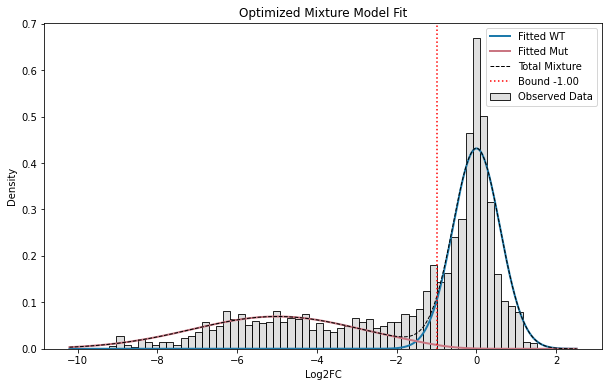


=== CUTOFFS ===
Log2FC at LLR > 2 (WT):      -0.9873
Log2FC at LLR < -2 (Mutant): -1.7631


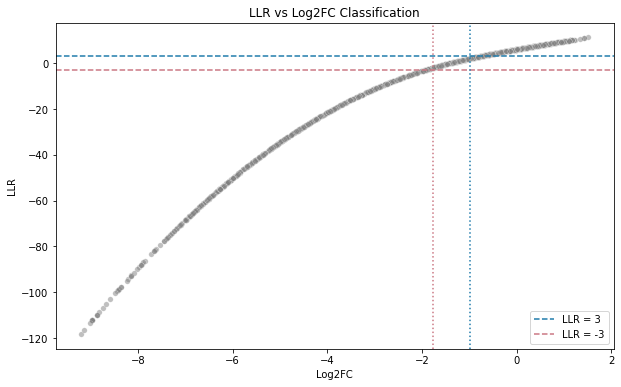

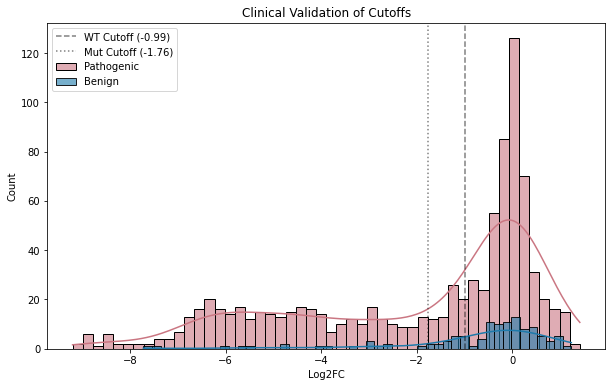

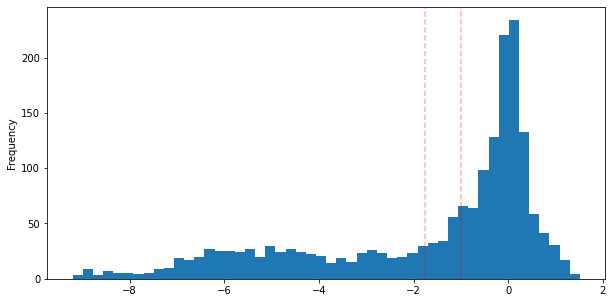

In [3]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from scipy.optimize import minimize
import matplotlib.pyplot as plt
import seaborn as sns
import polars as pl

# ==========================================
# 1. SETUP & DATA LOADING
# ==========================================
log2fc_values = df['log2fc'].dropna().to_numpy()
FIXED_BOUND = -1 # Hard biological limit
FIXED_MU_PERTURBED = -5 # Fixed mean for mutant distribution

# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================
def get_convolved_pdf(x_data, mu, sigma_bio, bound, sigma_error):
    """
    Computes the PDF of a Truncated Normal (intrinsic) convolved with Normal (noise).
    """
    var_prior = sigma_bio**2
    var_measurement = sigma_error**2
    sigma_combined = np.sqrt(var_prior + var_measurement)
    
    # A. Un-truncated distribution (Prior + Noise)
    log_py = stats.norm.logpdf(x_data, loc=mu, scale=sigma_combined)
    
    # B. Posterior Parameters for the Truncation Term
    var_post = 1.0 / (1.0 / var_prior + 1.0 / var_measurement)
    sigma_post = np.sqrt(var_post)
    mu_post = var_post * (mu / var_prior + x_data / var_measurement)
    
    # C. Truncation Adjustment Terms
    t = (bound - mu_post) / sigma_post
    log_post_cdf = stats.norm.logcdf(t)
    
    alpha = (bound - mu) / sigma_bio
    log_Z = stats.norm.logcdf(alpha)
    
    # Final Log PDF
    log_result = log_py + log_post_cdf - log_Z
    return np.exp(log_result)

def negative_log_likelihood(params):
    """
    Objective function for optimization.
    Params: [sigma_wt, mu_mut, sigma_mut, w_mut, sigma_error]
    """
    sigma_mut, w_mut, sigma_error = params
    
    
    # --- WT COMPONENT (Standard Normal Convolution) ---
    pdf_wt = stats.norm.pdf(log2fc_values, loc=0, scale=sigma_error)
    
    # --- MUTANT COMPONENT (Truncated Convolution) ---
    pdf_mut = get_convolved_pdf(log2fc_values, FIXED_MU_PERTURBED, sigma_mut, FIXED_BOUND, sigma_error)
    
    # --- MIXTURE ---
    pdf_mix = (1 - w_mut) * pdf_wt + w_mut * pdf_mut
    pdf_mix = np.maximum(pdf_mix, 1e-100) # Safety floor
    
    return -np.sum(np.log(pdf_mix))

# ==========================================
# 3. OPTIMIZATION
# ==========================================
# Guesses: sigma_wt, w_mut, sigma_error
initial_guess = [2.0, 0.2, 0.5]

bounds = [
    (0.5, 10.0),    # sigma_mut
    (0.01, 0.99),   # w_mut
    (0.01, 0.99)    # sigma_error
]

print("Optimizing parameters...")
res = minimize(negative_log_likelihood, initial_guess, bounds=bounds, method='L-BFGS-B')

# Unpack optimized parameters
opt_sigma_mut, opt_w_mut, opt_sigma_error = res.x

print("\n=== OPTIMIZED PARAMETERS ===")
print(f"Mutant Mean (Fixed):          {FIXED_MU_PERTURBED:.4f}")
print(f"Mutant Intrinsic Sig: {opt_sigma_mut:.4f}")
print(f"Measurement Error:    {opt_sigma_error:.4f}")
print(f"Bound (Fixed):        {FIXED_BOUND:.4f}")

# ==========================================
# 4. VISUALIZATION (FIT CHECK)
# ==========================================
plt.figure(figsize=(10, 6))
sns.histplot(log2fc_values, stat='density', bins=60, color='silver', alpha=0.5, label='Observed Data')

x_plot = np.linspace(min(log2fc_values)-1, max(log2fc_values)+1, 1000)

# WT Curve
y_wt = (1 - opt_w_mut) * stats.norm.pdf(x_plot, loc=0, scale=opt_sigma_error)

# Mut Curve
y_mut_raw = get_convolved_pdf(x_plot, FIXED_MU_PERTURBED, opt_sigma_mut, FIXED_BOUND, opt_sigma_error)
y_mut = opt_w_mut * y_mut_raw

# Total
y_total = y_wt + y_mut

plt.plot(x_plot, y_wt, color='#1D7AAB', lw=2, label='Fitted WT')
plt.plot(x_plot, y_mut, color='#CA7682', lw=2, label='Fitted Mut')
plt.plot(x_plot, y_total, color='black', linestyle='--', lw=1, label='Total Mixture')
plt.axvline(FIXED_BOUND, color='red', linestyle=':', label=f'Bound {FIXED_BOUND:.2f}')

plt.title("Optimized Mixture Model Fit")
plt.xlabel("Log2FC")
plt.ylabel("Density")
plt.legend()
plt.show()

# ==========================================
# 5. LLR CALCULATION
# ==========================================
def compute_perturbation_llr(df_in, mu_mut, sigma_mut, bound, sigma_error):
    """
    Calculates LLR using the consistent optimized parameters.
    """
    # Work on a copy (Pandas)
    df_out = df_in.copy()
    if isinstance(df_out, pl.DataFrame):
        df_out = df_out.to_pandas()
        
    log2fc = df_out["log2fc"].to_numpy()
    
    # Handle row-specific error if available, otherwise use optimized global error
    if "error_log2fc" in df_out.columns:
        row_error = df_out["error_log2fc"].fillna(sigma_error).to_numpy()
    else:
        row_error = np.full_like(log2fc, sigma_error)
        
    row_error = np.maximum(row_error, 1e-3) # Safety floor

    # --- Null Hypothesis (WT) ---
    # Model: Normal(0, scale = sqrt(Error^2 + Intrinsic_WT^2))
    # scale_wt = np.sqrt(row_error**2 + sigma_wt**2)
    loglik_wt = stats.norm.logpdf(log2fc, loc=0, scale=row_error)
    
    # --- Alt Hypothesis (Mutant) ---
    # Model: Convolved Truncated Normal
    pdt_mut = get_convolved_pdf(log2fc, mu_mut, sigma_mut, bound, row_error)
    loglik_mut = np.log(np.maximum(pdt_mut, 1e-100))  # Safety floor
    
    # --- Final Score ---
    # LLR = Log(P(WT)) - Log(P(Mut))
    # Positive = WT, Negative = Mutant
    df_out["perturbation_LLR"] = loglik_wt - loglik_mut
    
    return pl.from_pandas(df_out)

# Run Calculation
df_result_pl = compute_perturbation_llr(
    df, 
    mu_mut=FIXED_MU_PERTURBED, 
    sigma_mut=opt_sigma_mut,
    bound=FIXED_BOUND, 
    sigma_error=opt_sigma_error
)
df_result = df_result_pl.to_pandas()

# ==========================================
# 6. THRESHOLDS & VALIDATION PLOTS
# ==========================================
df_sorted = df_result.sort_values('perturbation_LLR')
x_vals = df_sorted['log2fc'].values
y_vals = df_sorted['perturbation_LLR'].values

# Interpolate Cutoffs
cutoff_wt = np.interp(2, y_vals, x_vals)
cutoff_mut = np.interp(-2, y_vals, x_vals)

print(f"\n=== CUTOFFS ===")
print(f"Log2FC at LLR > 2 (WT):      {cutoff_wt:.4f}")
print(f"Log2FC at LLR < -2 (Mutant): {cutoff_mut:.4f}")

# Plot 1: LLR Curve
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_result, x='log2fc', y='perturbation_LLR', alpha=0.5, color='grey', s=30)
plt.axhline(3, color='#1D7AAB', ls='--', label='LLR = 3')
plt.axhline(-3, color='#CA7682', ls='--', label='LLR = -3')
plt.axvline(cutoff_wt, color='#1D7AAB', ls=':')
plt.axvline(cutoff_mut, color='#CA7682', ls=':')
plt.title("LLR vs Log2FC Classification")
plt.xlabel("Log2FC")
plt.ylabel("LLR")
plt.legend()
plt.show()

# Plot 2: Pathogenic vs Benign Validation
pathogenic_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Pathogenic", "Likely pathogenic"])
).to_pandas()

benign_df = df_result_pl.filter(
    pl.col("clinvar_clnsig_clean_pp_strict").is_in(["Benign", "Likely benign"])
).to_pandas()

plt.figure(figsize=(10, 6))
sns.histplot(pathogenic_df["log2fc"], bins=50, kde=True, color="#CA7682", label="Pathogenic", alpha=0.6)
sns.histplot(benign_df["log2fc"], bins=50, kde=True, color="#1D7AAB", label="Benign", alpha=0.6)

plt.axvline(x=cutoff_wt, color='black', linestyle='--', alpha=0.5, label=f'WT Cutoff ({cutoff_wt:.2f})')
plt.axvline(x=cutoff_mut, color='black', linestyle=':', alpha=0.5, label=f'Mut Cutoff ({cutoff_mut:.2f})')

plt.title("Clinical Validation of Cutoffs")
plt.xlabel("Log2FC")
plt.legend()
plt.show()

# Plot combined histogram
df.log2fc.plot.hist(bins=50, figsize=(10,5))
plt.axvline(x=cutoff_wt, color='red', linestyle='--', alpha=0.3)
plt.axvline(x=cutoff_mut, color='red', linestyle='--', alpha=0.3)
plt.show()

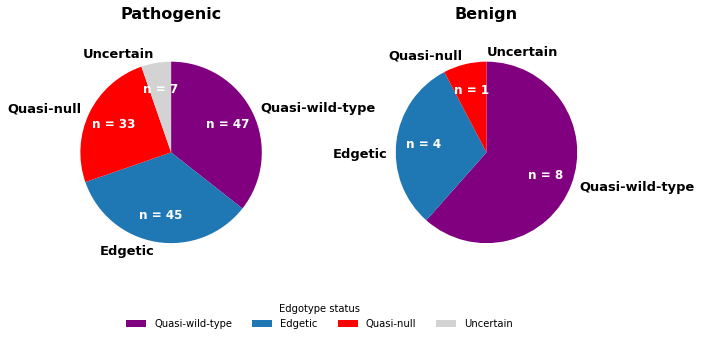

In [4]:
## Edgetic

df = df_result_pl.with_columns(
    pl.when(pl.col('perturbation_LLR').is_null())
    .then(pl.lit(None))
    .when(pl.col('perturbation_LLR') <= -2)
    .then(pl.lit('perturbed'))
    .when(pl.col('perturbation_LLR') >= 2)
    .then(pl.lit('unperturbed'))
    .otherwise(pl.lit('uncertain'))
    .alias('perturbation_status')
)

df = df.to_pandas()

def edgotype_status(status_list):
    status_list = status_list.to_list()
    # Filter out NaN values for counting
    non_null = [s for s in status_list if pd.notnull(s)]
    
    if len(non_null) == 0:
        return np.nan
    if len(non_null) == 1:
        if non_null[0] == 'Unperturbed':
            return 'Unperturbed-degree-1'
        elif non_null[0] == 'perturbed':
            return 'Perturbed-degree-1'
        elif non_null[0] == 'uncertain':
            return 'Uncertain-degree-1'
        else:
            return np.nan
    # 2+ measured PPIs
    if 'perturbed' in non_null and 'unperturbed' in non_null:
        return 'Edgetic'
    elif non_null.count('perturbed') >= 2:
        return 'Quasi-null'
    elif non_null.count('unperturbed') >= 2:
        return 'Quasi-wild-type'
    else:
        return 'Uncertain'
    
# N PPIs, N successful, N_perturbed, N_unperturbed, N-uncertain
edgotype = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(edgotype_status)
)

edgotype = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(edgotype_status)
)
edgotype = edgotype.to_frame().rename(columns={"perturbation_status": "edgotype_status"})
edgotype['n_ppi'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["ad_symbol"]
    .nunique())
edgotype['n_measured_ppi'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["log2fc"]
    .apply(lambda x: x.notnull().sum()))

for status in ['perturbed', 'unperturbed', 'uncertain']:
    edgotype[f'n_{status}'] = (df.loc[df['db_orf_id'] != 0, :]
            .groupby(["gene_variant"])
    ["perturbation_status"]
    .apply(lambda x: (x == status).sum()))
# TODO
edgotype = edgotype.reset_index()

n_b4 = edgotype.shape[0]
edgotype = pd.merge(edgotype, 
         df.loc[:, ['symbol', 
                    'gene_variant',
                    'clinvar_clnsig_clean',
                    ]].drop_duplicates(),
            on=["gene_variant"],
            how='left')


order = ['Quasi-wild-type', 'Edgetic', 'Quasi-null', 'Uncertain']

# from matplotlib.patches import Patch

# fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(6,12), gridspec_kw={'wspace': 0.4})

# for cat, ax in zip(['Pathogenic', 'Benign'], axs):
#     vc = (edgotype.loc[(edgotype['clinvar_clnsig_clean'] == cat)
#                  & (edgotype['n_measured_ppi'] >= 2), 
#                  'edgotype_status']
#                  .value_counts(dropna=True)
#                  .reindex(order)
#                  .fillna(0))
#     wedges, texts, autotexts = ax.pie(
#         vc,
#         labels=vc.index,
#         autopct=lambda x: f"n = {x / 100 * vc.sum():.0f}" if x > 0 else '',
#         startangle=90,
#         counterclock=False,
#         colors=['purple', 'C0', 'red', 'lightgrey'],
#         labeldistance=1.1,
#         textprops={'color': 'black', 'weight': 'bold'},
#         pctdistance=0.7,
#     )
#     ax.set_title(cat)
#     # Move "edgetic" label lower on the right pie
#     if cat == "Benign":
#         for t in texts:
#             if t.get_text() == "edgetic":
#                 x, y = t.get_position()
#                 t.set_position((x, y - 0.15))  # Move label lower
                
# # Custom legend
# legend_elements = [
#     Patch(facecolor='purple', label='quasi-wildtype'),
#     Patch(facecolor='C0', label='edgetic'),
#     Patch(facecolor='red', label='quasi-null'),
#     Patch(facecolor='lightgrey', label='uncertain'),
# ]

# # Adjust bbox_to_anchor to be within view (e.g., 0.1 or 0.2) 
# # or use loc='lower center' without a strict bbox to test visibility
# fig.legend(
#     handles=legend_elements,
#     title="Edgotype status",
#     loc="upper center",
#     bbox_to_anchor=(0.5, 0.15), 
#     ncol=2
# )

# plt.show()

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 1. Adjusted figsize to be wider than tall for side-by-side pies
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))

# 2. Reserve space at the bottom (bottom=0.2 means 20% of figure height)
fig.subplots_adjust(bottom=0.25, wspace=0.3)

for cat, ax in zip(['Pathogenic', 'Benign'], axs):
    vc = (edgotype.loc[(edgotype['clinvar_clnsig_clean'] == cat)
                 & (edgotype['n_measured_ppi'] >= 2), 
                 'edgotype_status']
                 .value_counts(dropna=True)
                 .reindex(order)
                 .fillna(0))
    
    wedges, texts, autotexts = ax.pie(
        vc,
        labels=vc.index,
        autopct=lambda x: f"n = {x / 100 * vc.sum():.0f}" if x > 0 else '',
        startangle=90,
        counterclock=False,
        colors=['purple', 'C0', 'red', 'lightgrey'],
        labeldistance=1.1,
        textprops={'color': 'black', 'weight': 'bold', 'fontsize': 13},
        pctdistance=0.7,
    )
    ax.set_title(cat, fontsize=16, weight='bold', pad=20)

    for autotext in autotexts:
        autotext.set_fontsize(12)
        autotext.set_weight('bold')
        autotext.set_color('white')
    
    # Move "edgetic" label lower on the right pie
    
    if cat == "Benign":
        for t in texts:
            if t.get_text() == "Edgetic":
                x, y = t.get_position()
                t.set_position((x, y - 0.15))

legend_elements = [
    Patch(facecolor='purple', label='Quasi-wild-type'),
    Patch(facecolor='C0', label='Edgetic'),
    Patch(facecolor='red', label='Quasi-null'),
    Patch(facecolor='lightgrey', label='Uncertain'),
]

# 3. Use loc="lower center" and move it slightly up from 0
fig.legend(
    handles=legend_elements,
    title="Edgotype status",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.05),
    ncol=4,          # Set to 4 to keep it on one line if space allows
    frameon=False    # Cleaner look for papers
)

plt.show()

In [5]:
# Table with LLR/perturbation status for Ross Stewart (Predrag Lab, NM paper)

df[['symbol', 'aa_change', 'ad_symbol', 'consensus_score', 'wt_consensus_score', 'log2fc','perturbation_LLR', 'perturbation_status']].to_csv(f'{outputs_dir}/ppi_level_scores_perturbation_status_for_Ross_260212.csv', index=False)
df[['symbol', 'aa_change', 'ad_symbol', 'consensus_score', 'wt_consensus_score', 'log2fc','perturbation_LLR', 'perturbation_status']]

,symbol,aa_change,ad_symbol,consensus_score,wt_consensus_score,log2fc,perturbation_LLR,perturbation_status
0,GFAP,Leu352Pro,GFAP,425.384752,267.516891,0.667143,8.366394,unperturbed
1,PLP1,Trp128Arg,PI16,2.301599,386.424013,-6.874605,-66.075313,perturbed
2,LITAF,Ser118Pro,GGA3,175.912676,400.835487,-1.183568,1.085057,uncertain
3,VHL,Arg126Trp,HSF2BP,42.828824,266.664224,-2.610472,-7.876311,perturbed
4,COQ8A,Gly272Asp,REEP6,11.537525,342.228292,-4.774844,-31.409368,perturbed
...,...,...,...,...,...,...,...,...
1836,HMBS,Arg167Trp,PICK1,489.189567,542.017345,-0.147659,5.442488,unperturbed
1837,KCNJ2,Arg312His,KCNJ2,23.126773,549.901791,-4.513088,-27.905061,perturbed
1838,TPM1,Asn279His,KXD1,2.593831,543.312732,-7.242769,-73.354636,perturbed
1839,KRT6A,Glu163Lys,TRIM54,150.297144,328.841853,-1.124390,1.366805,uncertain


In [6]:
edgotype

,gene_variant,edgotype_status,n_ppi,n_measured_ppi,n_perturbed,n_unperturbed,n_uncertain,symbol,clinvar_clnsig_clean
0,ACSF3_Arg10Trp,Perturbed-degree-1,1,1,1,0,0,ACSF3,VUS
1,ACSF3_Arg471Trp,Quasi-wild-type,3,3,0,3,0,ACSF3,Conflicting
2,ACSF3_Arg558Trp,Quasi-null,3,3,3,0,0,ACSF3,Pathogenic
3,ACSF3_Asp457Asn,Quasi-null,3,3,3,0,0,ACSF3,VUS
4,ACSF3_Glu359Lys,Quasi-null,3,3,3,0,0,ACSF3,Pathogenic
...,...,...,...,...,...,...,...,...,...
497,VHL_Tyr112His,Perturbed-degree-1,1,1,1,0,0,VHL,Pathogenic
498,VHL_Tyr134Cys,NaN,1,1,0,1,0,VHL,Pathogenic
499,VHL_Val125Ala,NaN,1,1,0,1,0,VHL,Pathogenic
500,ZMYND10_Leu266Pro,Quasi-null,2,2,2,0,0,ZMYND10,Pathogenic


In [7]:
all_assays_df = pd.read_csv('../../../3_integrated_assay_results/3_outputs/VarChAMP_data_supp_mat_PP.tsv', sep='\t')
all_assays_df['gene_variant'] = (all_assays_df['symbol'] + '_' +
                                all_assays_df['aa_change'].fillna('wt'))
all_assays_df

,symbol,ensembl_gene_id,aa_change,HGVS_c,clinvar_clnsig_clean,clinvar_clnsig_clean_pp_strict,dualipa_score,imaging_score,ppi_score,dualipa_hit,imaging_hit,ppi_hit,dualipa_DACC_accession_id,imaging_DACC_accession_id,ppi_DACC_accession_id,gene_variant
0,ABCD1,ENSG00000101986,Arg389Gly,NC_000023.11:g.153736195C>G,Pathogenic,Pathogenic,NaN,0.693378,NaN,NaN,False,NaN,NaN,IGVFDS4288KLWA,NaN,ABCD1_Arg389Gly
1,ABCD1,ENSG00000101986,Arg518Gln,NC_000023.11:g.153740156G>A,Pathogenic,Pathogenic,NaN,0.784993,NaN,NaN,False,NaN,NaN,IGVFDS4288KLWA,NaN,ABCD1_Arg518Gln
2,ACSF3,ENSG00000176715,Ala17Pro,NC_000016.10:g.89100730G>C,Benign,Benign,-1.256830,NaN,NaN,False,NaN,NaN,IGVFDS0761PJSK,NaN,NaN,ACSF3_Ala17Pro
3,ACSF3,ENSG00000176715,Ala197Thr,NC_000016.10:g.89101270G>A,Conflicting,Conflicting,-0.814021,NaN,NaN,False,NaN,NaN,IGVFDS0761PJSK,NaN,NaN,ACSF3_Ala197Thr
4,ACSF3,ENSG00000176715,Arg10Trp,NC_000016.10:g.89100709C>T,VUS,VUS,NaN,NaN,0.673632,NaN,NaN,True,NaN,NaN,IGVFDS9876GIEQ,ACSF3_Arg10Trp
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1402,ZC4H2,ENSG00000126970,Pro201Ser,NC_000023.11:g.64917857G>A,Pathogenic,Likely pathogenic,NaN,0.802143,NaN,NaN,False,NaN,NaN,IGVFDS4288KLWA,NaN,ZC4H2_Pro201Ser
1403,ZC4H2,ENSG00000126970,Val63Leu,NC_000023.11:g.64921855C>G,Pathogenic,Pathogenic,NaN,0.921160,NaN,NaN,False,NaN,NaN,IGVFDS4288KLWA,NaN,ZC4H2_Val63Leu
1404,ZMYND10,ENSG00000004838,Arg243Cys,NC_000003.12:g.50342543G>A,Benign,Likely benign,NaN,0.904041,NaN,NaN,False,NaN,NaN,IGVFDS4288KLWA,NaN,ZMYND10_Arg243Cys
1405,ZMYND10,ENSG00000004838,Leu266Pro,NC_000003.12:g.50342473A>G,Pathogenic,Pathogenic,NaN,NaN,0.402522,NaN,NaN,False,NaN,NaN,IGVFDS9876GIEQ,ZMYND10_Leu266Pro


In [8]:
# merge edgotype with all_assays_df on gene_variant for edgotype_status
all_assays_df = all_assays_df.merge(
    edgotype[['gene_variant', 'edgotype_status']],
    on='gene_variant',
    how='left'
)

all_assays_df

,symbol,ensembl_gene_id,aa_change,HGVS_c,clinvar_clnsig_clean,clinvar_clnsig_clean_pp_strict,dualipa_score,imaging_score,ppi_score,dualipa_hit,imaging_hit,ppi_hit,dualipa_DACC_accession_id,imaging_DACC_accession_id,ppi_DACC_accession_id,gene_variant,edgotype_status
0,ABCD1,ENSG00000101986,Arg389Gly,NC_000023.11:g.153736195C>G,Pathogenic,Pathogenic,NaN,0.693378,NaN,NaN,False,NaN,NaN,IGVFDS4288KLWA,NaN,ABCD1_Arg389Gly,NaN
1,ABCD1,ENSG00000101986,Arg518Gln,NC_000023.11:g.153740156G>A,Pathogenic,Pathogenic,NaN,0.784993,NaN,NaN,False,NaN,NaN,IGVFDS4288KLWA,NaN,ABCD1_Arg518Gln,NaN
2,ACSF3,ENSG00000176715,Ala17Pro,NC_000016.10:g.89100730G>C,Benign,Benign,-1.256830,NaN,NaN,False,NaN,NaN,IGVFDS0761PJSK,NaN,NaN,ACSF3_Ala17Pro,NaN
3,ACSF3,ENSG00000176715,Ala197Thr,NC_000016.10:g.89101270G>A,Conflicting,Conflicting,-0.814021,NaN,NaN,False,NaN,NaN,IGVFDS0761PJSK,NaN,NaN,ACSF3_Ala197Thr,NaN
4,ACSF3,ENSG00000176715,Arg10Trp,NC_000016.10:g.89100709C>T,VUS,VUS,NaN,NaN,0.673632,NaN,NaN,True,NaN,NaN,IGVFDS9876GIEQ,ACSF3_Arg10Trp,Perturbed-degree-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1402,ZC4H2,ENSG00000126970,Pro201Ser,NC_000023.11:g.64917857G>A,Pathogenic,Likely pathogenic,NaN,0.802143,NaN,NaN,False,NaN,NaN,IGVFDS4288KLWA,NaN,ZC4H2_Pro201Ser,NaN
1403,ZC4H2,ENSG00000126970,Val63Leu,NC_000023.11:g.64921855C>G,Pathogenic,Pathogenic,NaN,0.921160,NaN,NaN,False,NaN,NaN,IGVFDS4288KLWA,NaN,ZC4H2_Val63Leu,NaN
1404,ZMYND10,ENSG00000004838,Arg243Cys,NC_000003.12:g.50342543G>A,Benign,Likely benign,NaN,0.904041,NaN,NaN,False,NaN,NaN,IGVFDS4288KLWA,NaN,ZMYND10_Arg243Cys,NaN
1405,ZMYND10,ENSG00000004838,Leu266Pro,NC_000003.12:g.50342473A>G,Pathogenic,Pathogenic,NaN,NaN,0.402522,NaN,NaN,False,NaN,NaN,IGVFDS9876GIEQ,ZMYND10_Leu266Pro,Quasi-null


In [9]:
all_assays_df_filtered = all_assays_df.loc[
    (all_assays_df['edgotype_status'].notnull()) &
    (all_assays_df['dualipa_hit'].notnull()),
    :
]

all_assays_df_filtered

,symbol,ensembl_gene_id,aa_change,HGVS_c,clinvar_clnsig_clean,clinvar_clnsig_clean_pp_strict,dualipa_score,imaging_score,ppi_score,dualipa_hit,imaging_hit,ppi_hit,dualipa_DACC_accession_id,imaging_DACC_accession_id,ppi_DACC_accession_id,gene_variant,edgotype_status
5,ACSF3,ENSG00000176715,Arg471Trp,NC_000016.10:g.89145311C>T,Conflicting,Conflicting,-1.262592,NaN,0.119615,False,NaN,False,IGVFDS0761PJSK,NaN,IGVFDS9876GIEQ,ACSF3_Arg471Trp,Quasi-wild-type
6,ACSF3,ENSG00000176715,Arg558Trp,NC_000016.10:g.89154148C>T,Pathogenic,Likely pathogenic,-2.074148,NaN,0.500800,False,NaN,False,IGVFDS0761PJSK,NaN,IGVFDS9876GIEQ,ACSF3_Arg558Trp,Quasi-null
8,ACSF3,ENSG00000176715,Asp457Asn,NC_000016.10:g.89145269G>A,VUS,VUS,-1.312233,NaN,0.506415,False,NaN,False,IGVFDS0761PJSK,NaN,IGVFDS9876GIEQ,ACSF3_Asp457Asn,Quasi-null
9,ACSF3,ENSG00000176715,Glu359Lys,NC_000016.10:g.89114436G>A,Pathogenic,Likely pathogenic,-0.661990,NaN,0.466570,False,NaN,False,IGVFDS0761PJSK,NaN,IGVFDS9876GIEQ,ACSF3_Glu359Lys,Quasi-null
10,ACSF3,ENSG00000176715,Gly119Asp,NC_000016.10:g.89101037G>A,VUS,VUS,-0.814927,NaN,0.389524,False,NaN,False,IGVFDS0761PJSK,NaN,IGVFDS9876GIEQ,ACSF3_Gly119Asp,Quasi-null
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1328,TPM1,ENSG00000140416,Lys15Asn,NC_000015.10:g.63042874G>T,Conflicting,Conflicting,3.010470,0.711876,0.244512,True,False,False,IGVFDS0761PJSK,IGVFDS4288KLWA,IGVFDS9876GIEQ,TPM1_Lys15Asn,Quasi-wild-type
1329,TPM1,ENSG00000140416,Lys248Glu,NC_000015.10:g.63062615A>G,Pathogenic,Pathogenic,-0.422631,0.701268,0.159065,False,False,False,IGVFDS0761PJSK,IGVFDS4288KLWA,IGVFDS9876GIEQ,TPM1_Lys248Glu,Quasi-wild-type
1332,TPM1,ENSG00000140416,Met8Arg,NC_000015.10:g.63042852T>G,Pathogenic,Likely pathogenic,-0.075582,0.594221,0.161538,False,False,False,IGVFDS0761PJSK,IGVFDS4288KLWA,IGVFDS9876GIEQ,TPM1_Met8Arg,Quasi-wild-type
1333,TPM1,ENSG00000140416,Ser215Leu,NC_000015.10:g.63062219C>T,Pathogenic,Likely pathogenic,0.730045,0.657773,0.135948,False,False,False,IGVFDS0761PJSK,IGVFDS4288KLWA,IGVFDS9876GIEQ,TPM1_Ser215Leu,Quasi-wild-type


In [10]:
all_assays_df_filtered.to_csv('./tmp/edgotype_dualipa_luke.tsv', sep='\t', index=False)

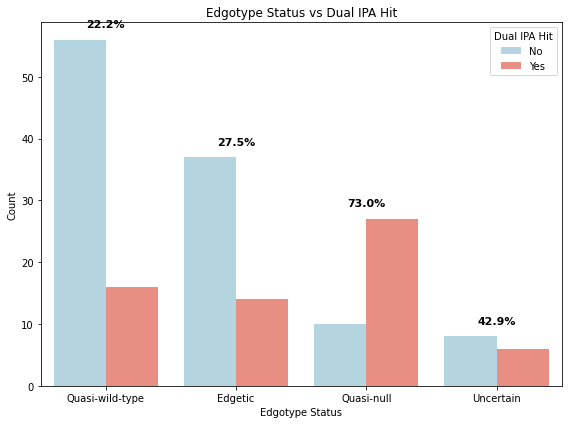

In [11]:
# plot edgotype_status vs dualipa_hit with % hit above bars
plt.figure(figsize=(8, 6))
ax = sns.countplot(
    data=all_assays_df_filtered,
    x='edgotype_status',
    hue='dualipa_hit',
    order=order,
    palette=['lightblue', 'salmon']
)
plt.title("Edgotype Status vs Dual IPA Hit")
plt.xlabel("Edgotype Status")
plt.ylabel("Count")
plt.legend(title='Dual IPA Hit', loc='upper right', labels=['No', 'Yes'])

# Calculate and add % of hit=Yes for each edgotype_status
for i, status in enumerate(order):
    subset = all_assays_df_filtered[all_assays_df_filtered['edgotype_status'] == status]
    total = len(subset)
    if total > 0:
        pct_yes = (subset['dualipa_hit'] == 1).sum() / total * 100
        # Get the height of the taller bar for positioning
        max_height = subset['dualipa_hit'].value_counts().max()
        ax.text(i, max_height + 2, f'{pct_yes:.1f}%', ha='center', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

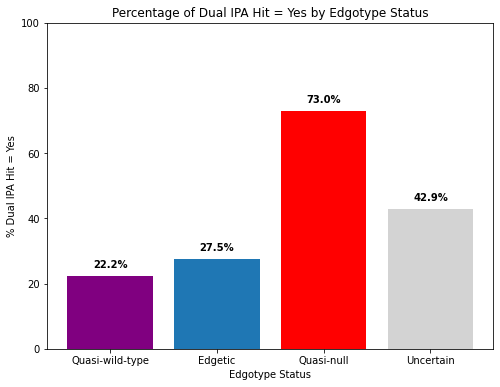

In [12]:
# Calculate percentage of dualipa_hit = 1 for each edgotype_status
hit_pct = (all_assays_df_filtered
           .groupby('edgotype_status')['dualipa_hit']
           .mean() * 100)
hit_pct = hit_pct.reindex(order)

plt.figure(figsize=(8, 6))
bars = plt.bar(hit_pct.index, hit_pct.values, color=['purple', 'C0', 'red', 'lightgrey'])
plt.title("Percentage of Dual IPA Hit = Yes by Edgotype Status")
plt.xlabel("Edgotype Status")
plt.ylabel("% Dual IPA Hit = Yes")
plt.ylim(0, 100)

# Add percentage labels on bars
for bar, pct in zip(bars, hit_pct.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, 
             f'{pct:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.show()

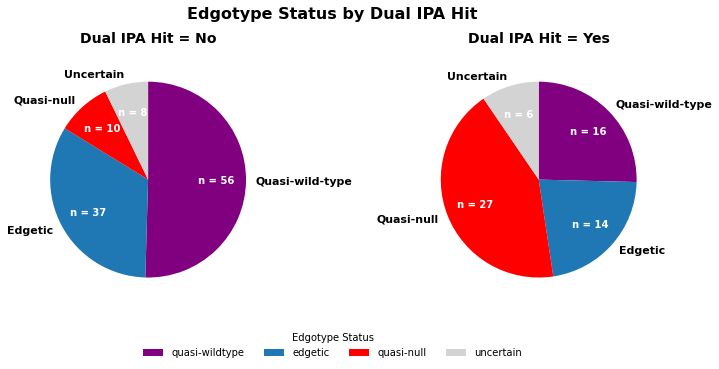

In [13]:
from matplotlib.patches import Patch

# Plot edgotype_status vs dualipa_hit as pie charts
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
fig.subplots_adjust(bottom=0.2, wspace=0.4)

for hit_status, ax in zip([0, 1], axs):
    subset = all_assays_df_filtered[all_assays_df_filtered['dualipa_hit'] == hit_status]
    vc = subset['edgotype_status'].value_counts().reindex(order).fillna(0)
    
    wedges, texts, autotexts = ax.pie(
        vc,
        labels=vc.index,
        autopct=lambda x: f"n = {x / 100 * vc.sum():.0f}" if x > 0 else '',
        startangle=90,
        counterclock=False,
        colors=['purple', 'C0', 'red', 'lightgrey'],
        labeldistance=1.1,
        textprops={'color': 'black', 'weight': 'bold', 'fontsize': 11},
        pctdistance=0.7,
    )
    title = "Dual IPA Hit = Yes" if hit_status == 1 else "Dual IPA Hit = No"
    ax.set_title(title, fontsize=14, weight='bold', pad=15)
    
    for autotext in autotexts:
        autotext.set_fontsize(10)
        autotext.set_weight('bold')
        autotext.set_color('white')

legend_elements = [
    Patch(facecolor='purple', label='quasi-wildtype'),
    Patch(facecolor='C0', label='edgetic'),
    Patch(facecolor='red', label='quasi-null'),
    Patch(facecolor='lightgrey', label='uncertain'),
]

fig.legend(
    handles=legend_elements,
    title="Edgotype Status",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.02),
    ncol=4,
    frameon=False
)

plt.suptitle("Edgotype Status by Dual IPA Hit", fontsize=16, weight='bold', y=1.02)
plt.show()

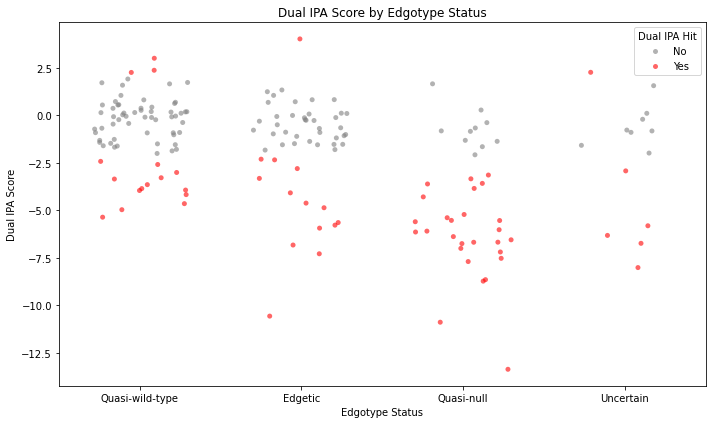

In [14]:
# Plot dualipa_score for each edgotype_status, colored by dualipa_hit
plt.figure(figsize=(10, 6))

# Stripplot with jitter for visibility
ax = sns.stripplot(
    data=all_assays_df_filtered,
    x='edgotype_status',
    y='dualipa_score',
    order=order,
    hue='dualipa_hit',
    palette={0: 'grey', 1: 'red'},
    dodge=False,
    alpha=0.6,
    jitter=0.3,
    size=5
)

plt.title("Dual IPA Score by Edgotype Status")
plt.xlabel("Edgotype Status")
plt.ylabel("Dual IPA Score")

# Fix legend with correct colors and labels
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=['No', 'Yes'], title='Dual IPA Hit', loc='upper right')

plt.tight_layout()
plt.show()

In [15]:
edgotype

,gene_variant,edgotype_status,n_ppi,n_measured_ppi,n_perturbed,n_unperturbed,n_uncertain,symbol,clinvar_clnsig_clean
0,ACSF3_Arg10Trp,Perturbed-degree-1,1,1,1,0,0,ACSF3,VUS
1,ACSF3_Arg471Trp,Quasi-wild-type,3,3,0,3,0,ACSF3,Conflicting
2,ACSF3_Arg558Trp,Quasi-null,3,3,3,0,0,ACSF3,Pathogenic
3,ACSF3_Asp457Asn,Quasi-null,3,3,3,0,0,ACSF3,VUS
4,ACSF3_Glu359Lys,Quasi-null,3,3,3,0,0,ACSF3,Pathogenic
...,...,...,...,...,...,...,...,...,...
497,VHL_Tyr112His,Perturbed-degree-1,1,1,1,0,0,VHL,Pathogenic
498,VHL_Tyr134Cys,NaN,1,1,0,1,0,VHL,Pathogenic
499,VHL_Val125Ala,NaN,1,1,0,1,0,VHL,Pathogenic
500,ZMYND10_Leu266Pro,Quasi-null,2,2,2,0,0,ZMYND10,Pathogenic


In [16]:
# Add Edgotype status to orf_distance_final

orf_distance_final = pd.read_csv('../3_outputs/sqY2H/orf_distances_final.csv')
orf_distance_final

,db_orf_id,db_mut_id,num_edges,clinvar_clnsig_clean,norm_dist_rms,symbol,gene_variant,aa_change,clinvar_clnsig_clean_pp_strict,ppi_hit
0,54308,218855,1,Benign,0.016992,PKP2,PKP2_Ile487Ser,Ile487Ser,Likely benign,False
1,13320,204016,1,Pathogenic,0.272227,VHL,VHL_Gln123Arg,Gln123Arg,Pathogenic,False
2,11805,203605,2,Pathogenic,0.118744,SMAD3,SMAD3_Arg287Trp,Arg287Trp,Likely pathogenic,False
3,1668,214086,2,VUS,0.143641,THAP1,THAP1_Lys89Arg,Lys89Arg,VUS,False
4,100016069,2644,1,Conflicting,0.459287,KCNJ2,KCNJ2_Met301Val,Met301Val,Conflicting,False
...,...,...,...,...,...,...,...,...,...,...
497,8143,202839,2,Pathogenic,0.073335,SH3BP2,SH3BP2_Pro418His,Pro418His,Pathogenic,False
498,5585,215440,1,Conflicting,0.025051,CRYAB,CRYAB_Gly154Ser,Gly154Ser,Conflicting,False
499,7652,1846,5,Pathogenic,0.675331,STXBP1,STXBP1_Arg551Leu,Arg551Leu,Likely pathogenic,True
500,2803,200947,1,Benign,0.442500,HMBS,HMBS_Asp359Asn,Asp359Asn,Likely benign,False


In [18]:
# merge edgotype with all_assays_df on gene_variant for edgotype_status
orf_distance_final = orf_distance_final.merge(
    edgotype[['gene_variant', 'edgotype_status']],
    on='gene_variant',
    how='left'
)

orf_distance_final.rename(columns={'edgotype_status': 'Edgotype_class'}, inplace=True)

orf_distance_final

,db_orf_id,db_mut_id,num_edges,clinvar_clnsig_clean,norm_dist_rms,symbol,gene_variant,aa_change,clinvar_clnsig_clean_pp_strict,ppi_hit,Edgotype_class
0,54308,218855,1,Benign,0.016992,PKP2,PKP2_Ile487Ser,Ile487Ser,Likely benign,False,NaN
1,13320,204016,1,Pathogenic,0.272227,VHL,VHL_Gln123Arg,Gln123Arg,Pathogenic,False,NaN
2,11805,203605,2,Pathogenic,0.118744,SMAD3,SMAD3_Arg287Trp,Arg287Trp,Likely pathogenic,False,Quasi-wild-type
3,1668,214086,2,VUS,0.143641,THAP1,THAP1_Lys89Arg,Lys89Arg,VUS,False,Quasi-wild-type
4,100016069,2644,1,Conflicting,0.459287,KCNJ2,KCNJ2_Met301Val,Met301Val,Conflicting,False,Uncertain-degree-1
...,...,...,...,...,...,...,...,...,...,...,...
497,8143,202839,2,Pathogenic,0.073335,SH3BP2,SH3BP2_Pro418His,Pro418His,Pathogenic,False,Quasi-wild-type
498,5585,215440,1,Conflicting,0.025051,CRYAB,CRYAB_Gly154Ser,Gly154Ser,Conflicting,False,NaN
499,7652,1846,5,Pathogenic,0.675331,STXBP1,STXBP1_Arg551Leu,Arg551Leu,Likely pathogenic,True,Quasi-null
500,2803,200947,1,Benign,0.442500,HMBS,HMBS_Asp359Asn,Asp359Asn,Likely benign,False,Uncertain-degree-1


In [19]:
# save back to csv
orf_distance_final.to_csv('../3_outputs/sqY2H/orf_distances_final_with_edgotype.csv', index=False)